In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO')
CWD_PATH = os.getcwd()
print(CWD_PATH)

/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image as IPImage
#%pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless
#%pip install opencv-python

## Task 5. Depth from stereo

In [ ]:
# Paths
LEFT_PATH  = "images/stereo/octagon_left.png"
RIGHT_PATH = "images/stereo/octagon_right.png"
OUTPUT_DIR = Path("images/stereo/stereo_results")
OUTPUT_DIR.mkdir(exist_ok=True)

Left shape : (1080, 1920)
Right shape: (1080, 1920)


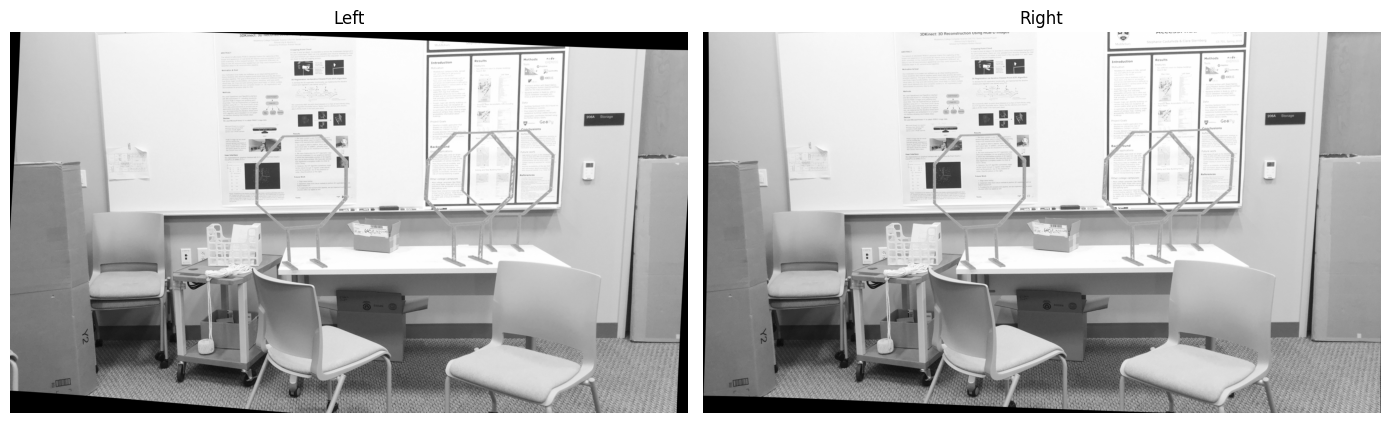

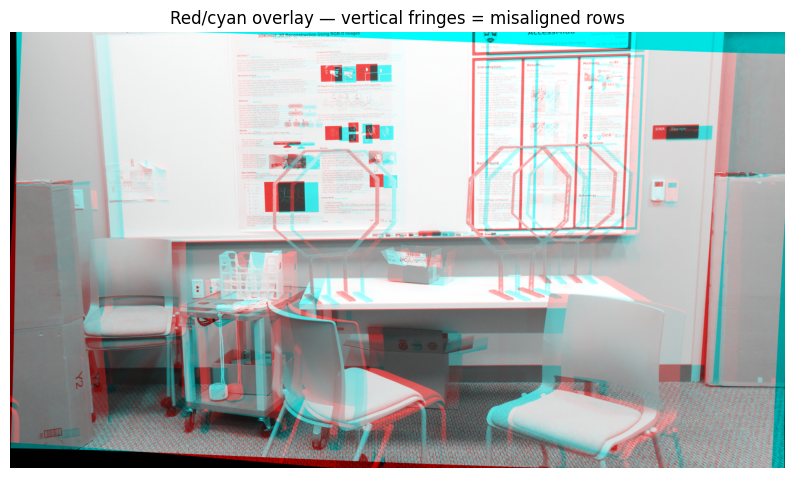

In [ ]:
##############################
# Load and inspect the pair
##############################
left  = cv2.imread(LEFT_PATH, cv2.IMREAD_GRAYSCALE)
right = cv2.imread(RIGHT_PATH, cv2.IMREAD_GRAYSCALE)

if left is None or right is None:
    raise FileNotFoundError("Could not load one or both images.")

print("Left shape :", left.shape)
print("Right shape:", right.shape)

if left.shape != right.shape:
    raise ValueError("Left and right images must be the same size.")

# Quick side-by-side
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(left,  cmap="gray"); ax[0].set_title("Left");  ax[0].axis("off")
ax[1].imshow(right, cmap="gray"); ax[1].set_title("Right"); ax[1].axis("off")
plt.tight_layout(); plt.show()

# Overlay check:  images should only differ by a horizontal shift.
# Blended in red/cyan to make misalignment visible.
overlay = np.dstack([left, right, right])   # red = left, cyan = right
plt.figure(figsize=(10, 6))
plt.imshow(overlay)
plt.title("Red/cyan overlay — vertical fringes = misaligned rows")
plt.axis("off")
plt.show()

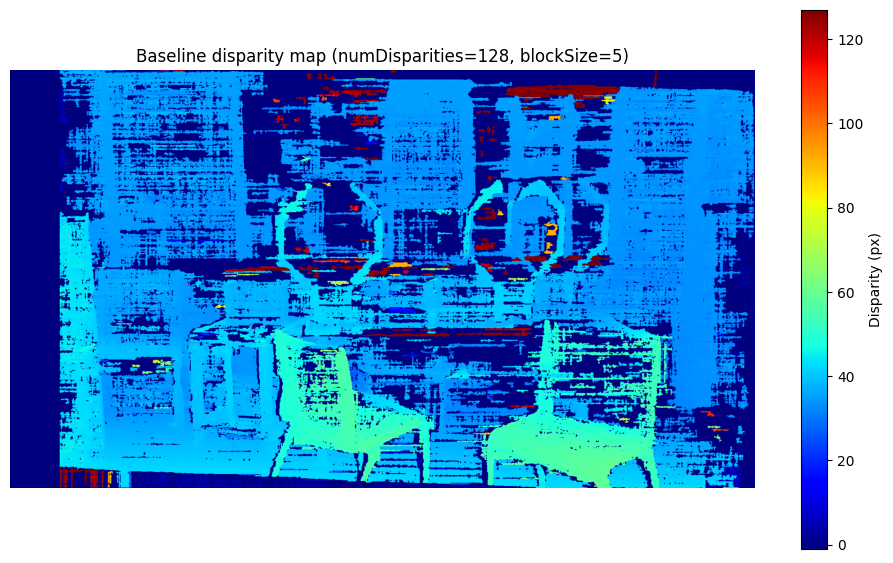

In [ ]:
##############################################
# Baseline disparity with StereoSGBM
############################################

def compute_disparity(left, right, num_disparities, block_size,
                      min_disparity=0, uniqueness=10,
                      speckle_window=100, speckle_range=2,
                      disp12_max_diff=1, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY):
    """
    Wrapper around StereoSGBM. num_disparities must be a multiple of 16.
    Returns a float32 disparity map in pixels.
    """
    if num_disparities % 16 != 0:
        raise ValueError("numDisparities must be a multiple of 16.")

    channels = 1   # we feed grayscale

    matcher = cv2.StereoSGBM_create(
        minDisparity=min_disparity,
        numDisparities=num_disparities,
        blockSize=block_size,
        P1=8  * channels * block_size * block_size,
        P2=32 * channels * block_size * block_size,
        disp12MaxDiff=disp12_max_diff,
        uniquenessRatio=uniqueness,
        speckleWindowSize=speckle_window,
        speckleRange=speckle_range,
        mode=mode,
    )

    disp = matcher.compute(left, right).astype(np.float32) / 16.0
    return disp

# Baseline: 128 disparities, 5x5 block
disp_base = compute_disparity(left, right,
                              num_disparities=128,
                              block_size=5)

plt.figure(figsize=(12, 7))
plt.imshow(disp_base, cmap="jet")
plt.colorbar(label="Disparity (px)")
plt.title("Baseline disparity map (numDisparities=128, blockSize=5)")
plt.axis("off")
plt.show()

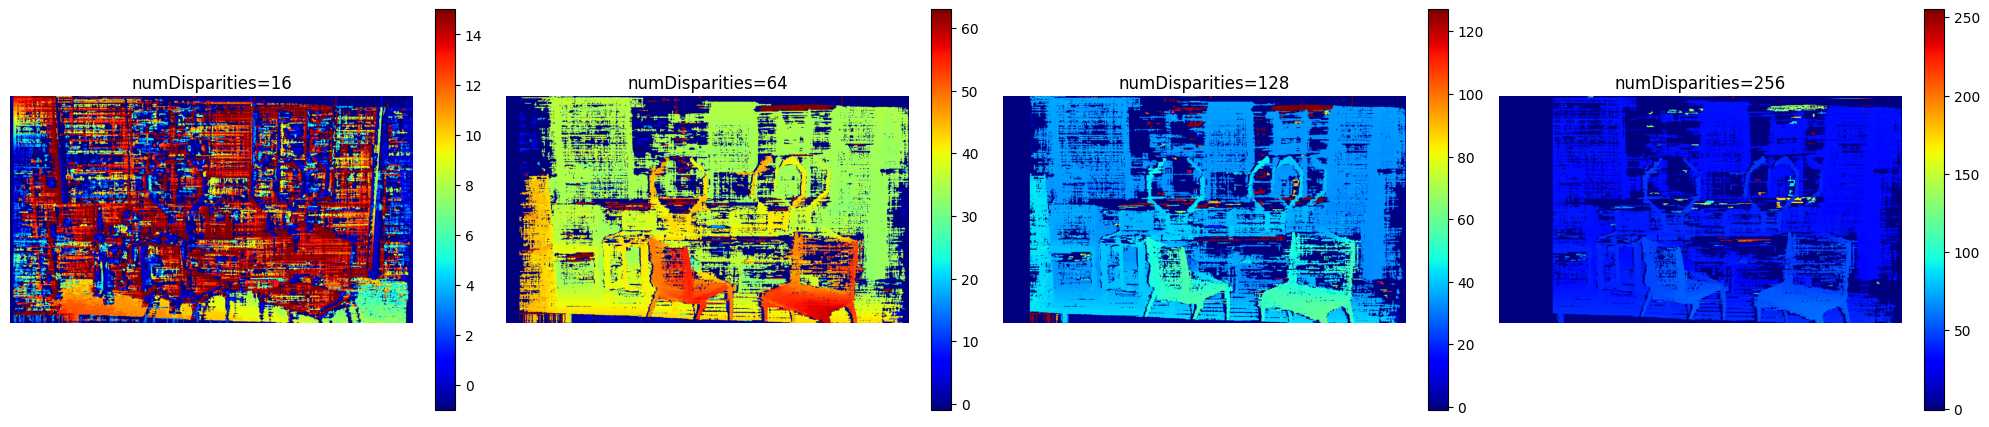

In [ ]:
####################################
# Sweep numDisparities
####################################
nd_values = [16, 64, 128, 256]

fig, axes = plt.subplots(1, len(nd_values), figsize=(5 * len(nd_values), 5))

for ax, nd in zip(axes, nd_values):
    d = compute_disparity(left, right,
                          num_disparities=nd,
                          block_size=5)
    im = ax.imshow(d, cmap="jet")
    ax.set_title(f"numDisparities={nd}")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.045)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sweep_numDisparities.png",
            dpi=140, bbox_inches="tight")
plt.show()

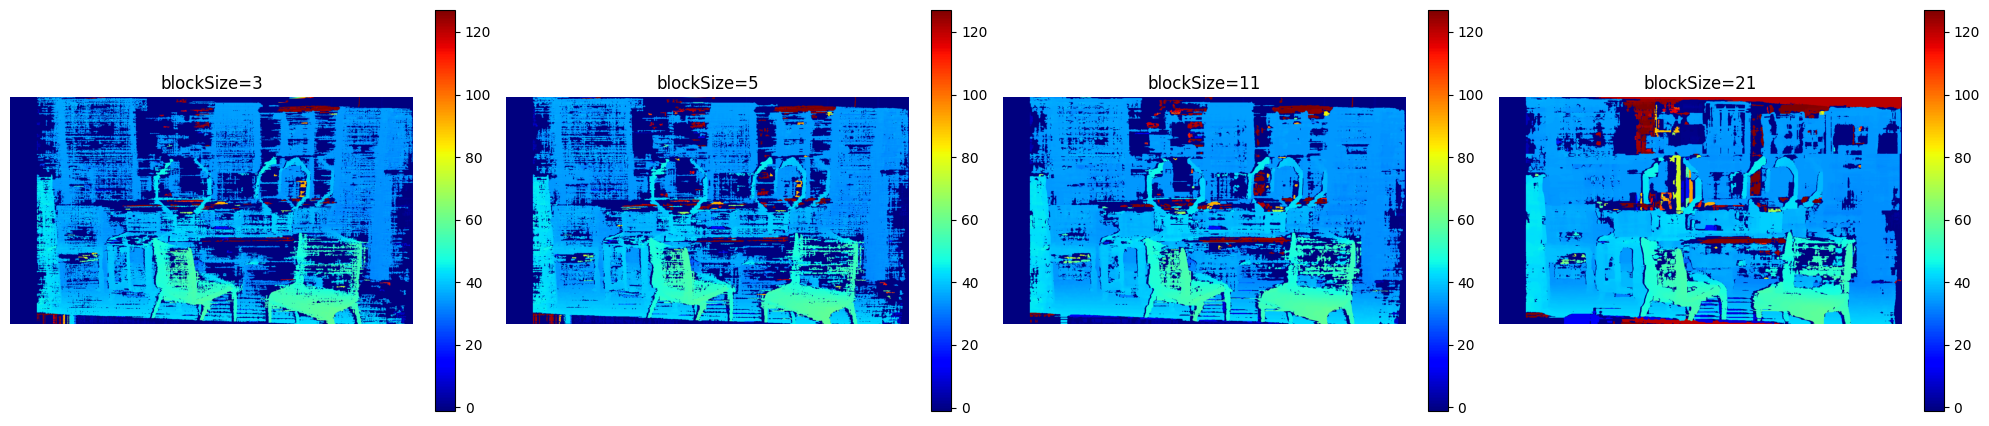

In [ ]:
##################################
# Sweep blockSize
##################################

bs_values = [3, 5, 11, 21]

fig, axes = plt.subplots(1, len(bs_values), figsize=(5 * len(bs_values), 5))

for ax, bs in zip(axes, bs_values):
    d = compute_disparity(left, right,
                          num_disparities=128,
                          block_size=bs)
    im = ax.imshow(d, cmap="jet")
    ax.set_title(f"blockSize={bs}")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.045)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sweep_blockSize.png",
            dpi=140, bbox_inches="tight")
plt.show()

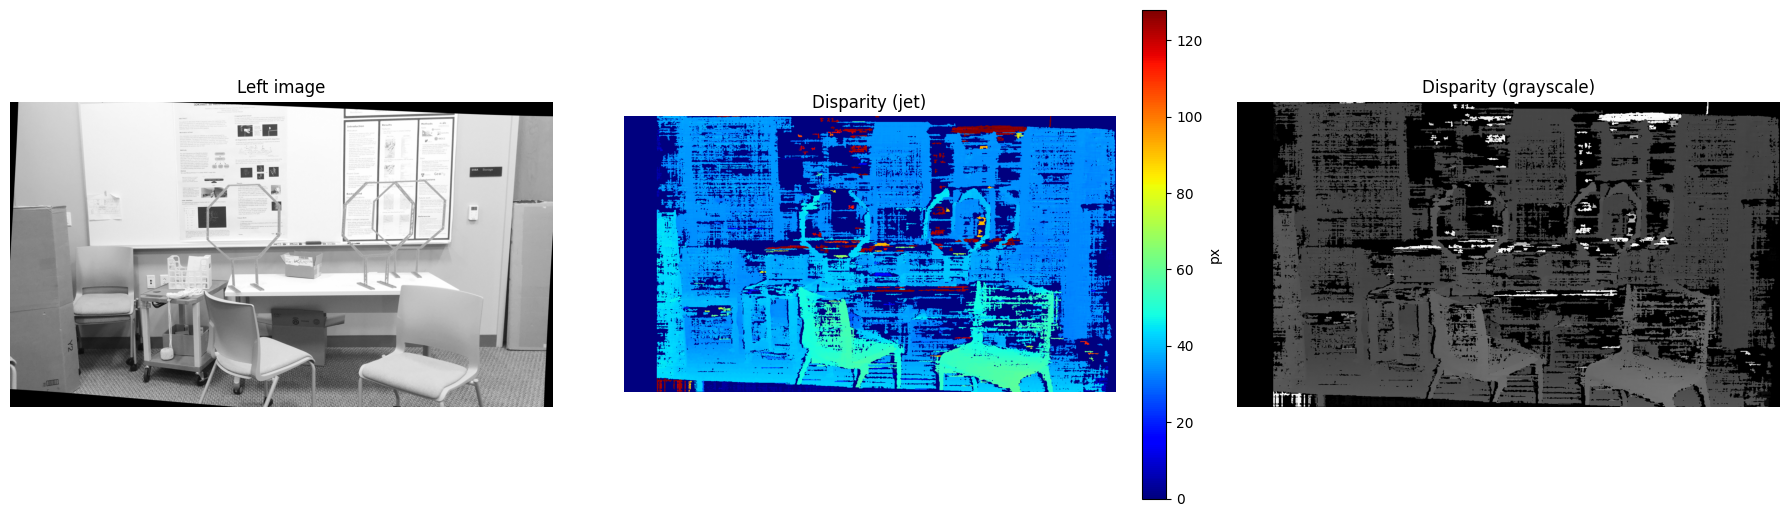

Verification guide:
 - In the 'jet' map, nearer objects are red/yellow.
 - Farther objects are blue/dark.


In [ ]:
#################################################
#Colourmap for verification of disparity ordering
################################################
# Use 'jet' or 'turbo' for visibility: warm colours = high disparity
# = near objects; cool colours = low disparity = far objects.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(left, cmap="gray")
axes[0].set_title("Left image"); axes[0].axis("off")

im = axes[1].imshow(disp_base, cmap="jet", vmin=0, vmax=128)
axes[1].set_title("Disparity (jet)"); axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.045, label="px")

axes[2].imshow(disp_base, cmap="gray", vmin=0, vmax=128)
axes[2].set_title("Disparity (grayscale)"); axes[2].axis("off")

plt.tight_layout(); plt.show()

print("Verification guide:")
print(" - In the 'jet' map, nearer objects are red/yellow.")
print(" - Farther objects are blue/dark.")

In [ ]:
# sampling two regions to compare their mean disparity
near_region = disp_base[400:500, 300:400]     # a near object
far_region  = disp_base[100:200, 300:400]     # a far wall

print(f"Mean disparity in near region: {near_region.mean():.2f} px")
print(f"Mean disparity in far region : {far_region.mean():.2f} px")
print("Expected: near > far  because disparity is inversely "
      "proportional to depth.")
print(f"Actual (near > far): {near_region.mean()>far_region.mean()}")

Mean disparity in near region: 24.36 px
Mean disparity in far region : 23.46 px
Expected: near > far  because disparity is inversely proportional to depth.
Actual (near > far): True


In [ ]:
# Normalize to 0-255 for saving as an image.
def save_disparity(disp, path, max_val=128):
    vis = np.clip(disp / max_val * 255, 0, 255).astype(np.uint8)
    vis = cv2.applyColorMap(vis, cv2.COLORMAP_JET)
    cv2.imwrite(str(path), vis)

save_disparity(disp_base, OUTPUT_DIR / "disparity_baseline.png")

print(f"Saved to: {OUTPUT_DIR}")

Saved to: images/stereo/stereo_results


**Parameter effects**<br>
`numDisparities`	extends the range of depths that can be matched. However, larger values add false matches in textureless regions and are more computationally expensive.<br>
`blockSize`	smooths the disparity map and reduces noise but it also blurs depth edges and can hide small nearby objects<br>
**what a proper stereo rig would fix**<br>
A properly built stereo rig uses two identical cameras rigidly mounted on a shared bar with a fixed, known baseline and synchronised shutters, so both views are captured at the same instant with matched exposure, focus, and white balance. Because the geometry between the cameras is fixed, the pair can be rectified using stereo calibration which eliminates vertical disparity and lets StereoSGBM search only horizontally. This removes vertical banding, reduces false matches, and produces a cleaner disparity map. Synchronised shutters also prevent temporal misalignment, so moving objects don't produce inconsistent disparities between the two views. Matched cameras with identical lenses and settings further minimise photometric differences, improving matching reliability in textureless regions.